# 5 · Résoudre $\mathbf K\mathbf u=\mathbf f$ : direct ou itératif

*Notebook 5 du cours. Il suppose les notebooks 3 et 4 (matrice $\mathbf K$ élastique, assemblage 2D/3D). Il ne suppose rien d'autre : l'algèbre linéaire utile est rappelée au fil du texte.*

Les notebooks précédents ont fabriqué un système linéaire $\widetilde{\mathbf K}\mathbf u=\mathbf f$ et l'ont résolu en appelant `spsolve`, une boîte noire. Le notebook 4 a pourtant montré que cette boîte noire devient **très coûteuse en 3D** (temps en $N^2$, mémoire de factorisation 5 fois plus grande qu'en 2D à $N$ comparable). Or l'optimisation topologique résout ce système **des centaines de fois** (une fois par itération de l'optimiseur), puis encore une fois par l'état adjoint. Choisir le bon solveur décide donc de ce qui est faisable ou non.

Il y a deux grandes familles :

- les méthodes **directes** (on factorise $\mathbf K=\mathbf L\mathbf L^\top$ ou $\mathbf L\mathbf U$ puis on résout deux systèmes triangulaires) : robustes, exactes à la précision machine, mais gourmandes en mémoire ;
- les méthodes **itératives** (on améliore une estimation par produits $\mathbf K\mathbf v$) : économes, **sans matrice** si on sait calculer $\mathbf K\mathbf v$, mais leur vitesse dépend du **conditionnement**.

**Plan.**
1. Un problème test : l'équation de la chaleur 2D (Poisson), dont on connaît la solution ;
2. Méthodes directes : coût, remplissage, ordre des inconnues, réutilisation de la factorisation ;
3. Méthodes itératives : de la descente de gradient au gradient conjugué (CG) ;
4. Conditionnement et préconditionnement de Jacobi, sur une structure avec éléments quasi vides ;
5. L'idée du multigrille ;
6. Direct contre itératif en 3D ;
7. Précision : pourquoi `float64` sur CPU.

Ce notebook promeut dans `src/aeroptimizer/fem/solvers.py` : une factorisation réutilisable (`DirectHandle`), le CG sans matrice (`conjugate_gradient`, `CGHandle`) et le préconditionneur de Jacobi.

In [1]:
import sys, time, inspect
from pathlib import Path

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import scipy.linalg as sla
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))

from aeroptimizer.fem import elements as el
from aeroptimizer.fem.solvers import (CGHandle, DirectHandle, ScipyDirect, TorchCG, check_device_dtype,
                                       conjugate_gradient, jacobi_preconditioner)
from aeroptimizer.grid import Grid, Connectivity
from aeroptimizer.materials import Orthotropic

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

## 1. Un problème test : l'équation de la chaleur (Poisson)

Pour comparer des solveurs, on veut un système **simple, de taille réglable et dont la solution est connue**. L'équation de la chaleur stationnaire dans un carré, température nulle sur le bord,

$$
-\Delta T=q\ \text{ dans }]0,1[^2,\qquad T=0\ \text{ au bord},
$$

convient. Elle a la même structure mathématique que le potentiel d'écoulement du projet (leçon 14) et elle est le « petit frère » scalaire de l'élasticité. On la discrétise avec le schéma à 5 points : sur une grille de $n\times n$ inconnues de pas $h=1/(n+1)$,

$$
4T_{i,j}-T_{i-1,j}-T_{i+1,j}-T_{i,j-1}-T_{i,j+1}=h^2q_{i,j}.
$$

La matrice $\mathbf A$ correspondante est creuse (5 coefficients par ligne), symétrique et définie positive (SPD), comme $\widetilde{\mathbf K}$. Avec $q=2\pi^2\sin(\pi x)\sin(\pi y)$, la solution exacte est $T=\sin(\pi x)\sin(\pi y)$, ce qui permet de **mesurer l'erreur** de discrétisation et de vérifier que le solveur ne la dégrade pas.

In [2]:
def lap1d(n):
    return sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(n, n), format="csr")

def poisson(n, d=2):
    # matrice du schéma à 5 (2D) ou 7 (3D) points sur n^d inconnues, non divisée par h^2
    I, T = sp.identity(n, format="csr"), lap1d(n)
    if d == 2:
        return (sp.kron(T, I) + sp.kron(I, T)).tocsr()
    return (sp.kron(sp.kron(T, I), I) + sp.kron(sp.kron(I, T), I) + sp.kron(sp.kron(I, I), T)).tocsr()

def probleme(n):
    h = 1.0 / (n + 1)
    x = np.arange(1, n + 1) * h
    X, Y = np.meshgrid(x, x, indexing="ij")
    exacte = np.sin(np.pi * X) * np.sin(np.pi * Y)
    return poisson(n), h ** 2 * 2 * np.pi ** 2 * exacte.ravel(), exacte.ravel()

print("n   inconnues   erreur max   erreur / h^2")
erreurs = []
for n in (7, 15, 31, 63, 127):
    A, b, exacte = probleme(n)
    T = spla.spsolve(A.tocsc(), b)
    e = np.abs(T - exacte).max(); h = 1 / (n + 1); erreurs.append((h, e))
    print(f"{n:3d} {n * n:10d} {e:12.3e} {e / h ** 2:12.4f}")
pente = np.polyfit(np.log([h for h, _ in erreurs]), np.log([e for _, e in erreurs]), 1)[0]
print(f"pente de l'erreur en fonction de h : {pente:.3f}  (schéma d'ordre 2)")

# propriétés spectrales : valeurs propres connues, lambda_ij = 4 sin^2(i pi h/2) + 4 sin^2(j pi h/2)
n = 31; h = 1 / (n + 1); A = poisson(n)
lmin_exact = 8 * np.sin(np.pi * h / 2) ** 2
lmax_exact = 8 * np.cos(np.pi * h / 2) ** 2
lmax = spla.eigsh(A, k=1, which="LA", return_eigenvectors=False)[0]
lmin = spla.eigsh(A, k=1, sigma=0, which="LM", return_eigenvectors=False)[0]
print(f"\nn = {n} : lambda_min = {lmin:.5f} (formule {lmin_exact:.5f}), lambda_max = {lmax:.5f} (formule {lmax_exact:.5f})")
print(f"conditionnement cond = lmax / lmin = {lmax / lmin:.0f}  ~  4 / (pi h)^2 = {4 / (np.pi * h) ** 2:.0f}")

n   inconnues   erreur max   erreur / h^2
  7         49    1.295e-02       0.8288
 15        225    3.219e-03       0.8241
 31        961    8.036e-04       0.8229
 63       3969    2.008e-04       0.8226
127      16129    5.020e-05       0.8225
pente de l'erreur en fonction de h : 2.002  (schéma d'ordre 2)

n = 31 : lambda_min = 0.01926 (formule 0.01926), lambda_max = 7.98074 (formule 7.98074)
conditionnement cond = lmax / lmin = 414  ~  4 / (pi h)^2 = 415


L'erreur décroît comme $h^2$, et les valeurs propres suivent la formule : le **conditionnement** $\kappa=\lambda_{\max}/\lambda_{\min}$ vaut environ $4/(\pi h)^2$ et **croît comme $h^{-2}$** quand on raffine. C'est la quantité qui va gouverner les méthodes itératives. On la retrouvera pour l'élasticité (notebook 4 : pente 1,8 à 2).

## 2. Méthodes directes

**Principe.** Pour $\mathbf A$ SPD, la factorisation de Cholesky $\mathbf A=\mathbf L\mathbf L^\top$ ($\mathbf L$ triangulaire) transforme $\mathbf A\mathbf x=\mathbf b$ en deux résolutions triangulaires : $\mathbf L\mathbf y=\mathbf b$ puis $\mathbf L^\top\mathbf x=\mathbf y$. Pour une matrice non symétrique on utilise LU ; c'est ce que fait `splu` (SuperLU) de SciPy, utilisé dans le projet.

**Trois variantes, trois coûts** (matrice du Poisson 2D, $N=n^2$ inconnues) :

1. **dense** : on stocke les $N^2$ coefficients, la factorisation coûte $\sim N^3/3$ opérations ;
2. **bande** : $\mathbf A$ ne couple que les inconnues à moins de $n$ rangs l'une de l'autre (numérotation en ordre C : un nœud voit ses voisins de la ligne d'au-dessus et d'en dessous). Cholesky préserve la bande : mémoire $N\cdot n$, coût $N\cdot n^2$ ;
3. **creux avec réordonnancement** : on **permute** les inconnues pour que $\mathbf L$ ait peu de coefficients non nuls. Le *remplissage* (fill-in) est le nombre de coefficients de $\mathbf L$ qui n'existaient pas dans $\mathbf A$.

In [3]:
def mo(x): return f"{x / 1e6:9.2f} Mo"

print(f"{'n':>4s} {'N':>7s} | {'dense (stockage)':>18s} {'bande (stockage)':>18s} {'LU creux MMD (L+U)':>20s} | {'t dense [s]':>11s} {'t creux [s]':>11s}")
for n in (16, 32, 48, 64):
    A = poisson(n); N = n * n
    t0 = time.perf_counter(); np.linalg.cholesky(A.toarray()) if n <= 48 else None; td = time.perf_counter() - t0
    t0 = time.perf_counter(); lu = spla.splu(A.tocsc(), permc_spec="MMD_AT_PLUS_A", options={"SymmetricMode": True}); tc = time.perf_counter() - t0
    print(f"{n:4d} {N:7d} | {mo(8 * N * N):>18s} {mo(8 * N * (n + 1)):>18s} {mo(8 * (lu.L.nnz + lu.U.nnz)):>20s} | {td if n <= 48 else float('nan'):11.3f} {tc:11.4f}")

   n       N |   dense (stockage)   bande (stockage)   LU creux MMD (L+U) | t dense [s] t creux [s]
  16     256 |            0.52 Mo            0.03 Mo              0.03 Mo |       0.001      0.0003
  32    1024 |            8.39 Mo            0.27 Mo              0.18 Mo |       0.013      0.0011
  48    2304 |           42.47 Mo            0.90 Mo              0.50 Mo |       0.059      0.0022
  64    4096 |          134.22 Mo            2.13 Mo              1.01 Mo |         nan      0.0037


Le stockage dense explose ($N^2$) ; la bande est déjà bien meilleure ; le creux réordonné est le plus économe. **Tout dépend de l'ordre des inconnues**, comme le montre la comparaison de plusieurs ordonnancements sur le même problème (SuperLU les propose en option `permc_spec`) :

Poisson 2D, n = 40, N = 1600, nnz(A) = 7840
    ordonnancement   nnz(L+U)  remplissage
           NATURAL     128078         16.3
            COLAMD      64902          8.3
           MMD_ATA      60338          7.7
     MMD_AT_PLUS_A      39942          5.1


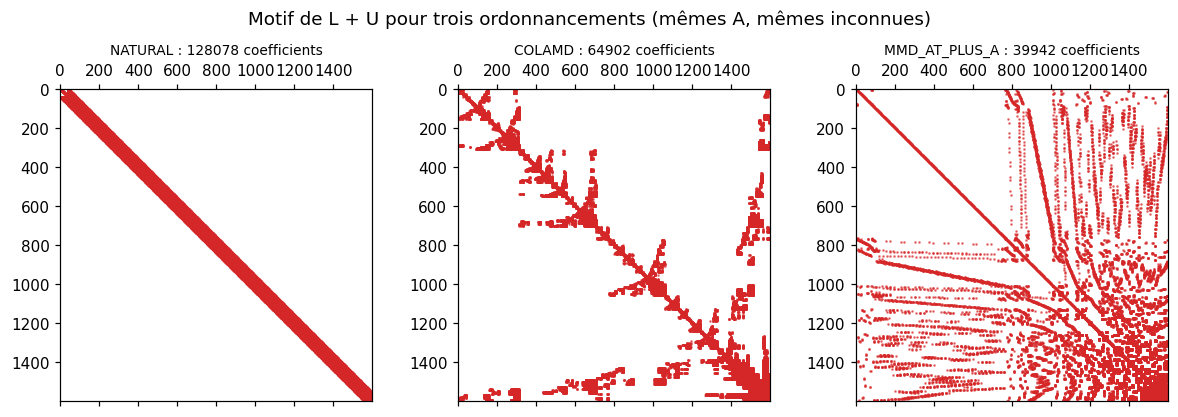

In [4]:
n = 40; A = poisson(n).tocsc()
print(f"Poisson 2D, n = {n}, N = {n * n}, nnz(A) = {A.nnz}")
print(f"{'ordonnancement':>18s} {'nnz(L+U)':>10s} {'remplissage':>12s}")
motifs = {}
for spec in ("NATURAL", "COLAMD", "MMD_ATA", "MMD_AT_PLUS_A"):
    lu = spla.splu(A, permc_spec=spec, options={"SymmetricMode": spec == "MMD_AT_PLUS_A"})
    nz = lu.L.nnz + lu.U.nnz
    print(f"{spec:>18s} {nz:10d} {nz / A.nnz:12.1f}")
    motifs[spec] = lu

fig, axs = plt.subplots(1, 3, figsize=(11, 3.7))
for ax, spec in zip(axs, ("NATURAL", "COLAMD", "MMD_AT_PLUS_A")):
    lu = motifs[spec]
    ax.spy((lu.L + lu.U).tocsr(), markersize=0.25, color="C3")
    ax.set_title(f"{spec} : {lu.L.nnz + lu.U.nnz} coefficients", fontsize=9)
plt.suptitle("Motif de L + U pour trois ordonnancements (mêmes A, mêmes inconnues)", y=1.0); plt.tight_layout(); plt.show()

L'ordre « naturel » donne une bande pleine ; les ordonnancements de type **degré minimum** (COLAMD, MMD) ont un remplissage bien moindre. Le projet utilise `MMD_AT_PLUS_A` avec `SymmetricMode` (on exploite le fait que $\mathbf K$ est symétrique : ARCHITECTURE §5.3).

**Réutiliser la factorisation.** Factoriser coûte cher, résoudre avec $\mathbf L,\mathbf U$ déjà calculés est très bon marché. Or le projet résout **deux fois** avec la même matrice : l'état $\mathbf K\mathbf u=\mathbf f$ puis l'état adjoint $\mathbf K\boldsymbol\lambda=\partial J/\partial\mathbf u$ (notebook 7). Comme $\mathbf K$ est symétrique, la **même** factorisation sert aux deux. C'est le contrat C-SOLVE-01, réalisé par `DirectHandle`, qui garde la factorisation :

In [5]:
A = poisson(100).tocsc(); N = A.shape[0]
rng = np.random.default_rng(0)
t0 = time.perf_counter(); h_dir = ScipyDirect().factorize(A); t_fact = time.perf_counter() - t0
b1, b2 = torch.from_numpy(rng.standard_normal(N)), torch.from_numpy(rng.standard_normal(N))
t0 = time.perf_counter(); y1 = h_dir.solve(b1); y2 = h_dir.solve(b2); t_solve = (time.perf_counter() - t0) / 2
print(f"N = {N} : factorisation {t_fact * 1e3:.1f} ms, une résolution {t_solve * 1e3:.2f} ms  (rapport {t_fact / t_solve:.0f})")
print("factorisations effectuées pour 2 résolutions :", h_dir.n_factorisations)
print("résidus relatifs :", [float(torch.linalg.norm(torch.from_numpy(A @ y.numpy()) - b) / torch.linalg.norm(b)) for y, b in ((y1, b1), (y2, b2))])
print(f"remplissage : {h_dir.fill_in:.1f}")

N = 10000 : factorisation 9.4 ms, une résolution 0.40 ms  (rapport 23)
factorisations effectuées pour 2 résolutions : 1
résidus relatifs : [2.808502984077013e-15, 2.5213543829320834e-15]
remplissage : 7.5


À tous les coûts, **le solveur direct reste la référence** : il fournit la solution à la précision machine et ne dépend pas du conditionnement. Son inconvénient, vu au notebook 4, est le remplissage en 3D.

## 3. Méthodes itératives : de la descente de gradient au gradient conjugué

**Idée.** Résoudre $\mathbf A\mathbf x=\mathbf b$ pour $\mathbf A$ SPD revient à **minimiser** l'énergie $\Phi(\mathbf x)=\tfrac12\mathbf x^\top\mathbf A\mathbf x-\mathbf b^\top\mathbf x$ (c'est le principe de l'énergie potentielle du notebook 2 !). Son gradient est $\nabla\Phi=\mathbf A\mathbf x-\mathbf b=-\mathbf r$, où $\mathbf r=\mathbf b-\mathbf A\mathbf x$ est le **résidu**. On construit une suite d'estimations qui descendent le long de $\Phi$, en n'utilisant que des **produits** $\mathbf A\mathbf v$.

Trois méthodes, de plus en plus fines :

- **Jacobi** (itération stationnaire) : $\mathbf x\leftarrow\mathbf x+\mathbf D^{-1}\mathbf r$, avec $\mathbf D=\mathrm{diag}(\mathbf A)$. **Gauss–Seidel** : même idée, en utilisant les valeurs déjà mises à jour.
- **Plus forte pente** : on descend selon $\mathbf r$, avec le pas optimal.
- **Gradient conjugué (CG)** : on descend selon des directions $\mathbf p_k$ **conjuguées** ($\mathbf p_i^\top\mathbf A\mathbf p_j=0$), de sorte qu'une descente ne défait pas les précédentes.

Sur une vallée étroite (grand conditionnement), la plus forte pente zigzague ; le CG n'a pas ce défaut. Visualisons-le sur un cas à 2 inconnues, avec les courbes de niveau de $\Phi$ :

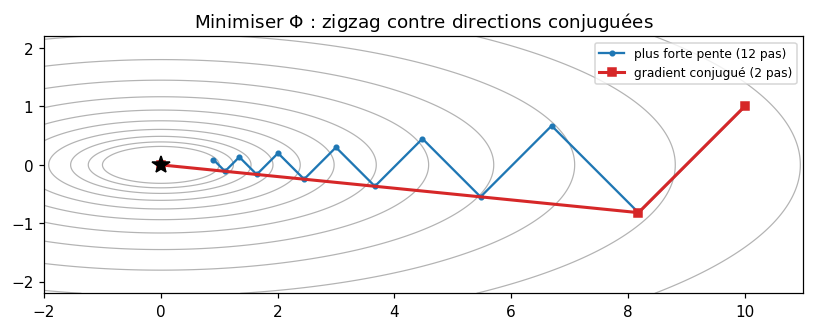

CG, erreur après 2 pas : 1.807312143953211e-15  (en arithmétique exacte, n pas suffisent pour n inconnues)
plus forte pente, erreur après 12 pas : 0.9043958863035738


In [6]:
A2 = np.diag([1.0, 10.0]); b2 = np.array([0.0, 0.0]); x0 = np.array([10.0, 1.0])     # conditionnement 10, solution = 0

def plus_forte_pente(A, b, x, n):
    chemin = [x.copy()]
    for _ in range(n):
        r = b - A @ x; x = x + (r @ r) / (r @ A @ r) * r; chemin.append(x.copy())
    return np.array(chemin)

def cg_chemin(A, b, x, n):
    chemin = [x.copy()]; r = b - A @ x; p = r.copy()
    for _ in range(n):
        Ap = A @ p; a = (r @ r) / (p @ Ap); x = x + a * p; rn = r - a * Ap
        p = rn + (rn @ rn) / (r @ r) * p; r = rn; chemin.append(x.copy())
    return np.array(chemin)

sd, cg2 = plus_forte_pente(A2, b2, x0, 12), cg_chemin(A2, b2, x0, 2)
g = np.linspace(-2, 11, 300); GX, GY = np.meshgrid(g, np.linspace(-2.2, 2.2, 300), indexing="ij")
Phi = 0.5 * (A2[0, 0] * GX ** 2 + 2 * A2[0, 1] * GX * GY + A2[1, 1] * GY ** 2)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.contour(GX, GY, Phi, levels=np.geomspace(0.5, 60, 12), colors="0.7", linewidths=0.8)
ax.plot(*sd.T, "o-", color="C0", ms=3, label="plus forte pente (12 pas)")
ax.plot(*cg2.T, "s-", color="C3", ms=5, lw=2, label="gradient conjugué (2 pas)")
ax.plot(0, 0, "k*", ms=12); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper right")
ax.set_title("Minimiser $\\Phi$ : zigzag contre directions conjuguées"); plt.tight_layout(); plt.show()
print("CG, erreur après 2 pas :", np.linalg.norm(cg2[-1]), " (en arithmétique exacte, n pas suffisent pour n inconnues)")
print("plus forte pente, erreur après 12 pas :", np.linalg.norm(sd[-1]))

Avec 2 inconnues, le CG termine en 2 pas : en arithmétique exacte il converge en **au plus $N$ itérations** pour $N$ inconnues, mais l'intérêt pratique est qu'il converge bien avant $N$ : l'erreur décroît comme $\left(\frac{\sqrt\kappa-1}{\sqrt\kappa+1}\right)^k$ (borne classique), alors que la plus forte pente décroît comme $\left(\frac{\kappa-1}{\kappa+1}\right)^k$. Le nombre d'itérations pour une précision donnée est donc proportionnel à $\sqrt\kappa$ pour le CG, à $\kappa$ pour la plus forte pente et pour Jacobi.

Voici le code du projet, qui n'a besoin que d'une fonction `matvec` (le produit $\mathbf A\mathbf v$) et non d'une matrice :

In [7]:
print(inspect.getsource(conjugate_gradient))

def conjugate_gradient(
    matvec: Callable[[torch.Tensor], torch.Tensor],
    b: torch.Tensor,
    *,
    x0: torch.Tensor | None = None,
    preconditioner: Preconditioner | None = None,
    tol: float = 1e-8,
    max_iter: int = 10_000,
) -> CGResult:
    """Preconditioned conjugate gradient for K x = b, K symmetric positive definite (matrix-free).

    Stops when the TRUE relative residual ||b - K x|| / ||b|| <= tol: when the cheap recursive
    residual says "converged", it is recomputed from x (one extra matvec) and, if it has drifted, replaced
    and the iteration continues. `max_iter` reached => `converged=False` (the caller decides).
    """
    norm_b = float(torch.linalg.norm(b))
    x = torch.zeros_like(b) if x0 is None else x0.clone()
    if norm_b == 0.0:
        return CGResult(torch.zeros_like(b), 0, True, (0.0,))
    precond = preconditioner or (lambda r: r)
    r = b - matvec(x)
    history = [float(torch.linalg.norm(r)) / norm_b]
    if history[0] <= tol:
        r

Points à noter dans ce code :

- **Rien n'est stocké** de $\mathbf A$ : seulement quelques vecteurs. Le seul accès à $\mathbf A$ est `matvec(p)`, une fois par itération. C'est ce qui rend possible l'**opérateur sans matrice** de la leçon 6 : $\mathbf K\mathbf v$ s'obtient élément par élément sans jamais assembler $\mathbf K$.
- Le critère d'arrêt porte sur le résidu **réel** $\|\mathbf b-\mathbf A\mathbf x\|/\|\mathbf b\|$ : le résidu récurrent, peu coûteux, dérive en arithmétique flottante, on le confirme donc avant de s'arrêter (contrat C-SOLVE-02).
- Un `x0` non nul permet un **départ à chaud** (warm start) : dans l'optimisation, la solution de l'itération précédente est un excellent point de départ.
- Si $\mathbf p^\top\mathbf A\mathbf p\le0$, la matrice n'est pas définie positive : on le signale au lieu de renvoyer un résultat faux.

**Comparons les méthodes sur le Poisson 2D** ($n=24$, $\kappa\approx250$) : résidu relatif en fonction du nombre de produits matrice-vecteur. On vérifie aussi que l'implémentation du projet donne la même solution que le solveur direct.

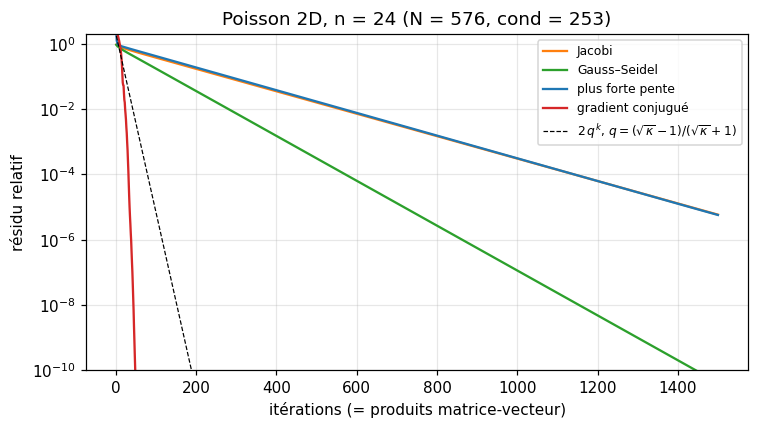

itérations pour résidu < 1e-6 : Jacobi > 1500, Gauss–Seidel 863, plus forte pente > 1500, CG 38
CG du projet vs solveur direct : erreur relative 5.2e-13, 49 itérations


In [8]:
n = 24; A = poisson(n); N = n * n; b = np.ones(N); nb = np.linalg.norm(b)
x_ref = spla.spsolve(A.tocsc(), b)
D = A.diagonal(); L_dense = np.tril(A.toarray())

def jacobi_iter(k):
    x = np.zeros(N); h = []
    for _ in range(k):
        x = x + (b - A @ x) / D; h.append(np.linalg.norm(b - A @ x) / nb)
    return h

def gauss_seidel(k):
    x = np.zeros(N); h = []
    for _ in range(k):
        x = x + sla.solve_triangular(L_dense, b - A @ x, lower=True); h.append(np.linalg.norm(b - A @ x) / nb)
    return h

def pente(k):
    x = np.zeros(N); h = []
    for _ in range(k):
        r = b - A @ x; Ar = A @ r; x = x + (r @ r) / (r @ Ar) * r; h.append(np.linalg.norm(b - A @ x) / nb)
    return h

K_MAX = 1500
h_j, h_gs, h_sd = jacobi_iter(K_MAX), gauss_seidel(K_MAX), pente(K_MAX)
res = conjugate_gradient(lambda v: torch.from_numpy(A @ v.numpy()), torch.from_numpy(b), tol=1e-10)
h_cg = list(res.residuals[1:])

kappa = (8 * np.cos(np.pi / (2 * (n + 1))) ** 2) / (8 * np.sin(np.pi / (2 * (n + 1))) ** 2)
q = (np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
for h, lab, c in ((h_j, "Jacobi", "C1"), (h_gs, "Gauss–Seidel", "C2"), (h_sd, "plus forte pente", "C0"), (h_cg, "gradient conjugué", "C3")):
    ax.semilogy(range(1, len(h) + 1), h, label=lab, color=c)
ks = np.arange(1, 250); ax.semilogy(ks, 2 * q ** ks, "k--", lw=0.8, label=r"$2\,q^k$, $q=(\sqrt{\kappa}-1)/(\sqrt{\kappa}+1)$")
ax.set_ylim(1e-10, 2); ax.set_xlabel("itérations (= produits matrice-vecteur)"); ax.set_ylabel("résidu relatif"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title(f"Poisson 2D, n = {n} (N = {N}, cond = {kappa:.0f})"); plt.tight_layout(); plt.show()

def iters(h, tol=1e-6): return next((i + 1 for i, v in enumerate(h) if v < tol), f"> {len(h)}")
print(f"itérations pour résidu < 1e-6 : Jacobi {iters(h_j)}, Gauss–Seidel {iters(h_gs)}, plus forte pente {iters(h_sd)}, CG {iters(h_cg)}")
print(f"CG du projet vs solveur direct : erreur relative {np.linalg.norm(res.x.numpy() - x_ref) / np.linalg.norm(x_ref):.1e}, {res.iterations} itérations")

(Jacobi et plus forte pente se superposent ici : la diagonale de la matrice de Poisson est constante, les deux méthodes sont équivalentes.) Le CG est de loin le plus rapide : quelques dizaines d'itérations contre plusieurs centaines à milliers pour les autres. Mesurons maintenant comment le nombre d'itérations du CG **croît avec le raffinement** (sans préconditionneur) :

In [9]:
print(f"{'n':>5s} {'N':>8s} {'cond':>9s} {'itérations CG':>14s} {'rapport':>8s}")
prec = None
cg_iters = {}
for n in (15, 31, 63, 127, 255):
    A = poisson(n); N = n * n
    kappa = 1 / np.tan(np.pi / (2 * (n + 1))) ** 2                     # lmax/lmin = cot^2(pi h / 2)
    r = conjugate_gradient(lambda v: torch.from_numpy(A @ v.numpy()), torch.ones(N), tol=1e-8)
    cg_iters[n] = r.iterations
    print(f"{n:5d} {N:8d} {kappa:9.0f} {r.iterations:14d} {'' if prec is None else f'{r.iterations / prec:8.2f}'}")
    prec = r.iterations

    n        N      cond  itérations CG  rapport
   15      225       103             27 
   31      961       414             58     2.15
   63     3969      1659            118     2.03
  127    16129      6640            237     2.01


  255    65025     26560            468     1.97


À chaque doublement de $n$ (donc $\kappa$ ×4), le nombre d'itérations **double** : il croît comme $\sqrt\kappa\propto h^{-1}$, conformément à la théorie. Chaque itération coûte un produit matrice-vecteur, proportionnel à $N$ : le coût total est donc $O(N\cdot n)=O(N^{3/2})$ en 2D et $O(N^{4/3})$ en 3D. Pour une élasticité 3D à un million d'inconnues, on peut s'attendre à quelques centaines d'itérations (extrapolation de la tendance mesurée au §6), chacune étant un produit creux : c'est incomparablement moins cher que la factorisation.

## 4. Conditionnement et préconditionnement

Le **préconditionnement** remplace $\mathbf A\mathbf x=\mathbf b$ par un système équivalent mieux conditionné, via une matrice $\mathbf M\approx\mathbf A$ facile à inverser : le CG préconditionné résout $\mathbf M^{-1}\mathbf A\mathbf x=\mathbf M^{-1}\mathbf b$ en une itération qui applique $\mathbf M^{-1}$ au résidu. Le plus simple est **Jacobi** : $\mathbf M=\mathrm{diag}(\mathbf A)$.

Sur le Poisson, la diagonale vaut 4 partout : **Jacobi ne change rien** (il ne fait que diviser par une constante). Vérifions-le, puis voyons où Jacobi est utile.

In [10]:
n = 63; A = poisson(n); N = n * n
mv = lambda v: torch.from_numpy(A @ v.numpy())
r0 = conjugate_gradient(mv, torch.ones(N), tol=1e-8)
r1 = conjugate_gradient(mv, torch.ones(N), preconditioner=jacobi_preconditioner(torch.from_numpy(A.diagonal().copy())), tol=1e-8)
print(f"Poisson n = {n} : CG sans préconditionneur {r0.iterations} itérations, avec Jacobi {r1.iterations} itérations")

Poisson n = 63 : CG sans préconditionneur 118 itérations, avec Jacobi 118 itérations


### L'élasticité avec des éléments quasi vides

Dans l'optimisation topologique, la rigidité d'un élément est $s_e=\varepsilon_s+(1-\varepsilon_s)\bar\rho_e^{\,p}$ (SIMP, FORMALISM §3.2). Un élément « vide » ($\bar\rho=0$) n'est pas supprimé : il garde la rigidité $\varepsilon_s$ (par défaut $10^{-9}$ dans le projet) pour que $\mathbf K$ reste inversible. La matrice a alors des coefficients qui varient de $10^{-9}$ à $1$ d'un nœud à l'autre : le **contraste de rigidité**. On le teste sur une console 2D en treillis (membrures et diagonales pleines, le reste vide), en faisant varier $\varepsilon_s$, avec la matrice élastique $\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P)$ du notebook 3.

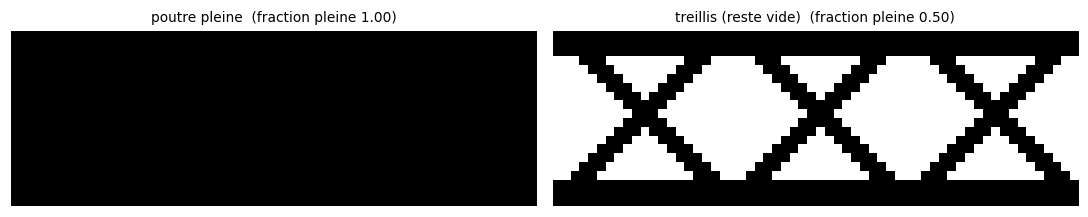

  design   eps_s |  CG simple  CG + Jacobi |    cond K  cond D^-1 K | direct [ms]


  pleine   1e-09 |        253          240 |   1.7e+05      1.6e+05 |         4.2


treillis   1e-03 |       1936          759 |   3.2e+05      1.7e+05 |         4.6


treillis   1e-06 |       8589          762 |   4.7e+07      1.7e+05 |         4.6


treillis   1e-09 |      14728          762 |   4.7e+10      1.7e+05 |         4.5


In [11]:
def assembler(grille, Ke0, ncomp, s_e):
    # K = sum_e s_e A_e^T Ke0 A_e, creuse. Même fonction que notebook 4, avec un facteur s_e par élément.
    ed = Connectivity(grille, ncomp).edof.numpy(); Ne, m = ed.shape; N = grille.n_dofs(ncomp)
    lignes = np.broadcast_to(ed[:, :, None], (Ne, m, m)); colonnes = np.broadcast_to(ed[:, None, :], (Ne, m, m))
    valeurs = s_e[:, None, None] * Ke0.numpy()[None]
    return sp.coo_matrix((valeurs.ravel(), (lignes.ravel(), colonnes.ravel())), shape=(N, N)).tocsr()

def console_2d(rho, eps, p=3.0):
    nx, nz = rho.shape
    g = Grid((nx, nz), (1.0, 1.0))
    s = eps + (1 - eps) * rho.ravel() ** p                                  # SIMP, FORMALISM §3.2
    K = assembler(g, el.elasticity_ke0(2, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(2)), 2, s)
    noeuds = np.arange(g.n_nodes).reshape(nx + 1, nz + 1)
    bloques = (2 * noeuds[0][:, None] + np.arange(2)).ravel()               # bord gauche encastré
    pm = np.ones(K.shape[0]); pm[bloques] = 0
    Kt = (sp.diags(pm) @ K @ sp.diags(pm) + sp.diags(1 - pm)).tocsc()
    f = np.zeros(K.shape[0]); f[2 * noeuds[-1, nz // 2] + 1] = -1.0          # force verticale au milieu du bord libre
    return Kt, f * pm

nx, nz = 60, 20
X, Z = np.meshgrid(np.arange(nx), np.arange(nz), indexing="ij")
treillis = np.zeros((nx, nz)); treillis[:, :3] = 1; treillis[:, -3:] = 1
for k in range(0, nx, 20):
    treillis[(np.abs(Z - (X - k)) <= 1.5) | (np.abs(Z - (k + 20 - X)) <= 1.5)] = 1
plein = np.ones((nx, nz))

fig, axs = plt.subplots(1, 2, figsize=(10, 2.2))
for ax, rho, t in zip(axs, (plein, treillis), ("poutre pleine", "treillis (reste vide)")):
    ax.imshow(rho.T, origin="lower", cmap="gray_r", vmin=0, vmax=1, aspect="equal"); ax.set_title(f"{t}  (fraction pleine {rho.mean():.2f})", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

def resoudre_cg(Kt, f, jacobi, tol=1e-8, max_iter=200000):
    mv = lambda v: torch.from_numpy(Kt @ v.numpy())
    pre = jacobi_preconditioner(torch.from_numpy(Kt.diagonal().copy())) if jacobi else None
    t0 = time.perf_counter()
    r = conjugate_gradient(mv, torch.from_numpy(f), preconditioner=pre, tol=tol, max_iter=max_iter)
    return r.iterations, time.perf_counter() - t0

print(f"{'design':>8s} {'eps_s':>7s} | {'CG simple':>10s} {'CG + Jacobi':>12s} | {'cond K':>9s} {'cond D^-1 K':>12s} | {'direct [ms]':>11s}")
for nom, rho in (("pleine", plein), ("treillis", treillis)):
    for eps in ((1e-9,) if nom == "pleine" else (1e-3, 1e-6, 1e-9)):
        Kt, f = console_2d(rho, eps)
        i0, _ = resoudre_cg(Kt, f, False); i1, _ = resoudre_cg(Kt, f, True)
        d = Kt.diagonal(); Dm = sp.diags(1 / np.sqrt(d)); Ks = (Dm @ Kt @ Dm).tocsc()           # D^{-1/2} K D^{-1/2}, mêmes valeurs propres que D^{-1}K
        conds = []
        for M in (Kt, Ks):
            lmax = spla.eigsh(M, k=1, which="LA", return_eigenvectors=False)[0]
            lmin = spla.eigsh(M, k=1, sigma=0, which="LM", return_eigenvectors=False)[0]
            conds.append(lmax / lmin)
        t0 = time.perf_counter(); DirectHandle(Kt).solve(torch.from_numpy(f)); td = time.perf_counter() - t0
        print(f"{nom:>8s} {eps:7.0e} | {i0:10d} {i1:12d} | {conds[0]:9.1e} {conds[1]:12.1e} | {td * 1e3:11.1f}")

**Lecture.**

- Sur la poutre pleine, le contraste n'existe pas : le CG simple et le CG de Jacobi font à peu près le même nombre d'itérations (le conditionnement vient de la finesse et de l'élancement de la poutre).
- Sur le treillis, le CG **simple** voit son nombre d'itérations exploser quand $\varepsilon_s$ diminue (le conditionnement de $\widetilde{\mathbf K}$ suit $1/\varepsilon_s$), alors que **Jacobi** le garde stable : la mise à l'échelle par la diagonale neutralise le contraste de rigidité entre éléments pleins et vides, ce qui est son rôle.
- Le solveur direct, lui, ne dépend ni de $\varepsilon_s$ ni du contraste : quelques millisecondes ici.

Jacobi ne résout cependant que le contraste d'échelle : il ne corrige pas le conditionnement de la **finesse** ($\propto h^{-2}$) ni de l'**élancement**. Les itérations restent de l'ordre de plusieurs centaines pour 2 500 inconnues, et elles croissent avec le raffinement. Vérifions-le sur la poutre pleine :

In [12]:
print(f"{'nz':>4s} {'nx':>4s} {'inconnues':>10s} {'CG Jacobi (itérations)':>24s}")
prev = None
for nzz in (10, 20, 40, 80):
    Kt, f = console_2d(np.ones((3 * nzz, nzz)), 1e-9)
    it, _ = resoudre_cg(Kt, f, True)
    print(f"{nzz:4d} {3 * nzz:4d} {Kt.shape[0]:10d} {it:24d}   {'' if prev is None else f'x{it / prev:.2f}'}")
    prev = it

  nz   nx  inconnues   CG Jacobi (itérations)
  10   30        682                      120   
  20   60       2562                      240   x2.00
  40  120       9922                      477   x1.99


  80  240      39042                      950   x1.99


À chaque doublement du raffinement, les itérations doublent à peu près (×$\sqrt4$), comme pour le Poisson : c'est la loi $\sqrt\kappa\propto h^{-1}$. Pour un raffinement fort, il faut un préconditionneur qui **annule** cette dépendance : le multigrille.

## 5. L'idée du multigrille

Observation clé : les itérations de **Jacobi pondéré** ($\mathbf x\leftarrow\mathbf x+\omega\mathbf D^{-1}\mathbf r$, $\omega<1$) sont inefficaces sur la solution globale, mais **amortissent très vite les erreurs oscillantes** (hautes fréquences). Pour la matrice de Poisson, le mode de Fourier $k$ est multiplié à chaque passe par $1-\omega\lambda_k/\mathrm{diag}$. On le calcule et on le vérifie numériquement :

facteur d'amortissement par passe, modes k = 1, 16, 63 :
  mesuré  : [ 0.9992  0.8047 -0.3325]
  formule : [ 0.9992  0.8047 -0.3325]


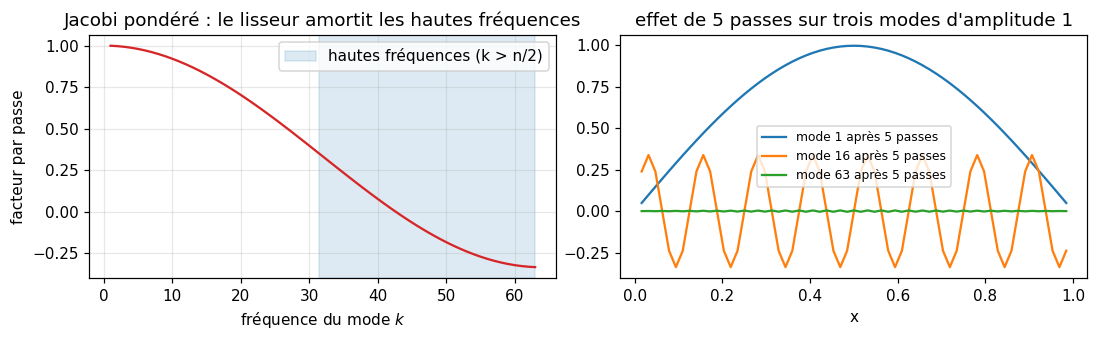

amplitude max après 5 passes, mode 1 / 16 / 63 : [0.996, 0.3375, 0.0041]


In [13]:
n = 63; h = 1 / (n + 1); omega = 2 / 3
T = lap1d(n).toarray()                                                    # Poisson 1D
modes = np.array([np.sin(k * np.pi * np.arange(1, n + 1) * h) for k in range(1, n + 1)])    # mode de Fourier k : sin(k pi x)
facteur_formule = 1 - omega * (2 - 2 * np.cos(np.arange(1, n + 1) * np.pi * h)) / 2
e = modes[[0, 15, 62]].copy()
e_apres = e - omega * (T @ e.T).T / 2                                       # une passe de Jacobi pondéré sur l'erreur : e <- e - w D^-1 A e
facteur_mesure = (e_apres * e).sum(1) / (e * e).sum(1)
print("facteur d'amortissement par passe, modes k = 1, 16, 63 :")
print("  mesuré  :", facteur_mesure); print("  formule :", facteur_formule[[0, 15, 62]])

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(range(1, n + 1), facteur_formule, color="C3")
axs[0].axvspan(n / 2, n, color="C0", alpha=0.15, label="hautes fréquences (k > n/2)")
axs[0].set_xlabel("fréquence du mode $k$"); axs[0].set_ylabel("facteur par passe"); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[0].set_title("Jacobi pondéré : le lisseur amortit les hautes fréquences")
x = np.arange(1, n + 1) * h
for k in (1, 16, 63):
    e = np.sin(k * np.pi * x) ; v = e.copy()
    for _ in range(5): v = v - omega * (T @ v) / 2
    axs[1].plot(x, v, label=f"mode {k} après 5 passes")
axs[1].legend(fontsize=8); axs[1].set_title("effet de 5 passes sur trois modes d'amplitude 1"); axs[1].set_xlabel("x")
plt.tight_layout(); plt.show()
print("amplitude max après 5 passes, mode 1 / 16 / 63 :", [round(float(np.abs(np.linalg.matrix_power(np.eye(n) - omega * T / 2, 5) @ np.sin(k * np.pi * x)).max()), 4) for k in (1, 16, 63)])

Le mode lent ($k=1$) n'est presque pas amorti (facteur $0{,}999$ par passe), les modes les plus rapides le sont fortement (facteur $-0{,}33$ pour $k=63$ : après 5 passes il reste $0{,}4\,\%$ de leur amplitude, contre $99{,}6\,\%$ pour le mode 1). Le poids $\omega$ est choisi pour cela : $2/3$ pour Poisson 1D (ici), $0{,}8$ pour Poisson 2D (dans le cycle en V ci-dessous). D'où l'idée : après quelques passes de **lissage**, il ne reste que de l'erreur lisse, qu'une grille **plus grossière** représente correctement et résout bien moins cher. Un **cycle en V** enchaîne :

1. quelques passes de lissage sur la grille fine ;
2. calcul du résidu, **restriction** à la grille grossière (une valeur pour 4 nœuds en 2D) ;
3. résolution (récursive : même cycle un niveau plus bas, jusqu'à une grille minuscule résolue directement) ;
4. **prolongation** (interpolation bilinéaire) de la correction vers la grille fine, puis quelques passes de lissage.

On ne l'utilise pas comme solveur mais comme **préconditionneur** du CG. Voici une version minimale pour le Poisson 2D (matrices de transfert bilinéaires, matrice grossière de Galerkin $\mathbf P^\top\mathbf A\mathbf P$, lissage symétrique : même nombre de passes avant et après, pour que le préconditionneur reste symétrique) :

In [14]:
def prolongation_1d(nc):
    nf = 2 * nc + 1; P = sp.lil_matrix((nf, nc))
    for j in range(nc):
        P[2 * j, j], P[2 * j + 1, j], P[2 * j + 2, j] = 0.5, 1.0, 0.5
    return P.tocsr()

def niveaux(n):
    # liste de (A, diag, P) du plus fin au plus grossier ; P absent au dernier niveau
    A, lv = poisson(n), []
    while n > 3:
        nc = (n - 1) // 2; P1 = prolongation_1d(nc); P = sp.kron(P1, P1).tocsr()
        lv.append((A, A.diagonal(), P)); A = (P.T @ A @ P).tocsr(); n = nc
    lv.append((A, A.diagonal(), None))
    return lv

def cycle_en_V(lv, l, b, nu=2, w=0.8):
    A, D, P = lv[l]
    if P is None: return spla.spsolve(A.tocsc(), b)                    # grille minuscule : solveur direct
    x = np.zeros_like(b)
    for _ in range(nu): x += w * (b - A @ x) / D                       # pré-lissage
    x += P @ cycle_en_V(lv, l + 1, P.T @ (b - A @ x), nu, w)            # correction grossière
    for _ in range(nu): x += w * (b - A @ x) / D                       # post-lissage
    return x

print(f"{'n':>5s} {'N':>8s} {'niveaux':>8s} {'CG simple':>10s} {'CG + Jacobi':>12s} {'CG + multigrille':>17s}")
for n in (15, 31, 63, 127, 255):
    lv = niveaux(n); A = lv[0][0]; N = n * n
    mv = lambda v: torch.from_numpy(A @ v.numpy())
    pre_mg = lambda r: torch.from_numpy(cycle_en_V(lv, 0, r.numpy()))
    b = torch.ones(N)
    a = conjugate_gradient(mv, b, tol=1e-8).iterations
    j = conjugate_gradient(mv, b, preconditioner=jacobi_preconditioner(torch.from_numpy(A.diagonal().copy())), tol=1e-8).iterations
    m = conjugate_gradient(mv, b, preconditioner=pre_mg, tol=1e-8).iterations
    print(f"{n:5d} {N:8d} {len(lv):8d} {a:10d} {j:12d} {m:17d}")

    n        N  niveaux  CG simple  CG + Jacobi  CG + multigrille
   15      225        3         27           27                 6
   31      961        4         58           58                 6
   63     3969        5        118          118                 6
  127    16129        6        237          237                 6


  255    65025        7        468          468                 6


Le CG multigrille converge en **6 itérations quelle que soit la finesse** ($n$ de 15 à 255), alors que le CG simple passe de 27 à 468. C'est la propriété recherchée : un préconditionneur dont l'efficacité **ne dépend pas de $h$**. Chaque cycle coûte $O(N)$, donc la résolution totale est $O(N)$, optimale.

Deux mises en garde honnêtes. (1) Ce multigrille est écrit ici seulement pour le Poisson sur une grille carrée. Pour l'élasticité avec contraste de rigidité $10^9$ (éléments quasi vides), les opérateurs de transfert et le lissage demandent plus de soin ; **cela n'est pas testé ici** et reste un risque identifié du projet (ARCHITECTURE R2, phase 6). (2) Le lisseur compte : avec $\omega=1$ au lieu de $0{,}8$, le nombre d'itérations à $n=63$ passe de 6 à 37 (essai hors notebook). Pour la limite du multigrille, le projet démarre avec Jacobi et le solveur direct, et ne promet le multigrille qu'en phase 6.

## 6. Direct contre itératif en 3D

Reprenons la console 3D du notebook 4 (cube $1\times1\times1$ encastré sur une face, chargé sur la face opposée) et comparons le solveur direct et le CG-Jacobi, à tolérance $10^{-8}$ sur le résidu.

In [15]:
def cube_3d(n):
    g = Grid((n,) * 3, (1.0 / n,) * 3)
    K = assembler(g, el.elasticity_ke0(3, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(3)), 3, np.ones(g.n_elems))
    noeuds = np.arange(g.n_nodes).reshape((n + 1,) * 3)
    bloques = (3 * noeuds[0].ravel()[:, None] + np.arange(3)).ravel()
    pm = np.ones(K.shape[0]); pm[bloques] = 0
    Kt = (sp.diags(pm) @ K @ sp.diags(pm) + sp.diags(1 - pm)).tocsc()
    f = np.zeros(K.shape[0]); f[3 * noeuds[-1].ravel() + 2] = -1.0 / (n + 1) ** 2
    return Kt, f * pm

lignes = []
print(f"{'n':>3s} {'inconnues':>10s} | {'direct [s]':>11s} {'L+U [M coef.]':>14s} | {'CG Jacobi [s]':>14s} {'itérations':>11s} | {'écart relatif des solutions':>28s}")
for n in (8, 12, 16, 20, 24):
    Kt, f = cube_3d(n); N = Kt.shape[0]
    if n <= 20:
        t0 = time.perf_counter(); h = ScipyDirect().factorize(Kt); u_d = h.solve(torch.from_numpy(f)); td = time.perf_counter() - t0
        nnz_lu = (h._lu.L.nnz + h._lu.U.nnz) / 1e6
    else:
        td, nnz_lu, u_d = float("nan"), float("nan"), None
    pre = TorchCG(tol=1e-8).handle(lambda v: torch.from_numpy(Kt @ v.numpy()), torch.from_numpy(Kt.diagonal().copy()))
    t0 = time.perf_counter(); u_c = pre.solve(torch.from_numpy(f)); tc = time.perf_counter() - t0
    ecart = float(torch.linalg.norm(u_c - u_d) / torch.linalg.norm(u_d)) if u_d is not None else float("nan")
    lignes.append((n, N, td, tc, pre.last.iterations))
    print(f"{n:3d} {N:10d} | {td:11.2f} {nnz_lu:14.1f} | {tc:14.3f} {pre.last.iterations:11d} | {ecart:28.1e}")

  n  inconnues |  direct [s]  L+U [M coef.] |  CG Jacobi [s]  itérations |  écart relatif des solutions
  8       2187 |        0.02            0.7 |          0.007          72 |                      1.4e-10


 12       6591 |        0.38            4.8 |          0.029         108 |                      1.1e-10


 16      14739 |        2.04           15.7 |          0.091         144 |                      1.1e-10


 20      27783 |       10.99           49.3 |          0.206         181 |                      9.2e-11


 24      46875 |         nan            nan |          0.460         217 |                          nan


**Lecture.** Les deux solveurs donnent la même solution (écart de l'ordre de $10^{-10}$, cohérent avec la tolérance $10^{-8}$ du CG sur le résidu). Le temps du solveur direct croît très vite avec $N$ : de 2 s à 15 000 inconnues à 11 s à 28 000, avec une factorisation de 49 millions de coefficients, alors que le CG ne coûte que quelques centaines de produits creux : 0,2 s à 28 000 inconnues, soit une cinquantaine de fois moins. Le nombre d'itérations croît lentement (environ proportionnel à $n$ : 72, 108, 144, 181, 217). C'est pourquoi le CG est le solveur retenu pour les grands problèmes 3D.

En contrepartie, le CG ne fournit que ce que la tolérance demande, et **réutiliser** l'information pour l'adjoint est moins direct : chaque système adjoint est une résolution CG de plus. Le compromis du projet (ARCHITECTURE §5.3) est donc : solveur direct en 2D et pour les petits 3D (jusqu'à environ 50 000 inconnues, adjoint gratuit), CG préconditionné au-delà.

## 7. Précision : pourquoi `float64` sur CPU

Les ordinateurs calculent avec une précision finie : `float32` ($\approx7$ chiffres) et `float64` ($\approx16$ chiffres). Le résidu atteignable par un solveur itératif est de l'ordre de $\varepsilon_{\rm mach}\,\kappa$ (précision machine fois conditionnement). Avec $\kappa\sim10^5$ (ordre de grandeur de la poutre ci-dessous), la borne donne $\approx6\cdot10^{-8}\times10^{5}\approx10^{-2}$ pour `float32` et $\approx10^{-11}$ pour `float64`. On le mesure sur la poutre 2D élancée (60×20) : on arrête le CG après $k$ itérations et on calcule le **vrai** résidu $\|\mathbf b-\mathbf K\mathbf x\|/\|\mathbf b\|$ (évalué avec la matrice correspondante) :

 torch.float64 : résidu réel minimal atteint = 2.3e-12


 torch.float32 : résidu réel minimal atteint = 1.0e-03


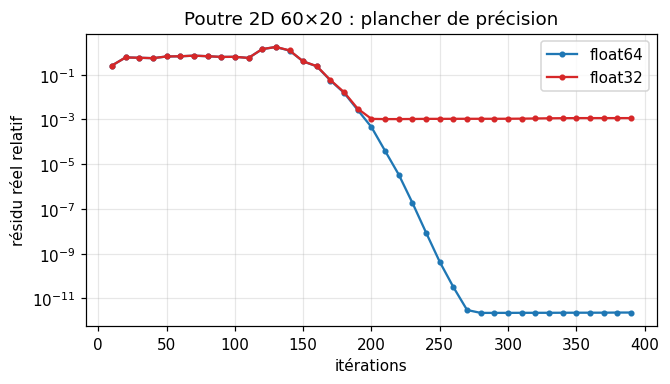


check_device_dtype('mps', float64) -> DeviceError : MPS does not support float64; use device='cpu' (reference) or CUDA.
PyTorch lui-même sur ce Mac : TypeError : Cannot convert a MPS Tensor to float64 dtype as the MPS framework doesn't support float64.


In [16]:
Kt, f = console_2d(plein, 1e-9)
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for dt, couleur in ((torch.float64, "C0"), (torch.float32, "C3")):
    K_dt = Kt.astype(np.float64 if dt == torch.float64 else np.float32)
    mv = lambda v: torch.from_numpy(K_dt @ v.numpy())
    b = torch.from_numpy(f).to(dt); pre = jacobi_preconditioner(torch.from_numpy(K_dt.diagonal().copy()))
    ks = list(range(10, 400, 10)); vrai = []
    for k in ks:
        x = conjugate_gradient(mv, b, preconditioner=pre, tol=1e-300, max_iter=k).x
        vrai.append(np.linalg.norm(f - K_dt.astype(np.float64) @ x.double().numpy()) / np.linalg.norm(f))
    ax.semilogy(ks, vrai, "o-", ms=3, color=couleur, label=str(dt).replace("torch.", ""))
    print(f"{str(dt):>14s} : résidu réel minimal atteint = {min(vrai):.1e}")
ax.set_xlabel("itérations"); ax.set_ylabel("résidu réel relatif"); ax.legend(); ax.grid(alpha=0.3, which="both")
ax.set_title("Poutre 2D 60×20 : plancher de précision"); plt.tight_layout(); plt.show()

# la règle du projet : float64 jamais sur MPS (GPU Apple), qui ne le supporte pas
try:
    check_device_dtype("mps", torch.float64)
except Exception as e:
    print(f"\ncheck_device_dtype('mps', float64) -> {type(e).__name__} : {e}")
if torch.backends.mps.is_available():
    try:
        torch.zeros(2, dtype=torch.float64, device="mps")
    except Exception as e:
        print(f"PyTorch lui-même sur ce Mac : {type(e).__name__} : {str(e)[:90]}")
else:
    print("(pas de GPU MPS sur cette machine : la vérification directe de PyTorch n'a pas été exécutée)")

**Lecture.** En `float64`, le résidu réel descend jusqu'à environ $2\cdot10^{-12}$ ; en `float32`, il **plafonne** à $10^{-3}$ (le CG ne peut pas faire mieux, quel que soit le nombre d'itérations ; la borne ci-dessus est un majorant) : fixer une tolérance de $10^{-8}$ en `float32` est donc impossible, et les gradients de l'optimisation, qui exigent des solutions précises (notebook 7), en seraient pollués. Le projet impose `float64` sur CPU comme référence ; le GPU Apple (MPS) ne supporte pas `float64`, ce que le code refuse explicitement (`DeviceError`, contrat C-SOLVE-09). Une version `float32` n'est envisageable qu'avec un préconditionneur de très bonne qualité (multigrille) et une tolérance adaptée, à valider séparément.

## À retenir

| Idée | Dans le projet |
|---|---|
| $\widetilde{\mathbf K}$ SPD : résoudre $\Leftrightarrow$ minimiser l'énergie $\tfrac12\mathbf u^\top\mathbf K\mathbf u-\mathbf f^\top\mathbf u$ | contrat : `K̃` symétrique (C-SOLVE-08), `check_symmetric` |
| Direct (LU creux, ordre `MMD_AT_PLUS_A`) : robuste, factorisation réutilisable ; remplissage et temps $\sim N^2$ en 3D | `DirectHandle` / `ScipyDirect.factorize` ; la même factorisation sert à l'état et à l'adjoint (C-SOLVE-01) |
| CG : une `matvec` par itération, rien d'autre ; $\sim\sqrt\kappa$ itérations ; $\kappa\propto h^{-2}$ | `conjugate_gradient`, `CGHandle`, `TorchCG` ; départ à chaud ; arrêt sur le résidu **réel** (C-SOLVE-02) |
| Jacobi supprime le contraste de rigidité (éléments quasi vides) mais pas le $h^{-2}$ | `jacobi_preconditioner` |
| Multigrille : nombre d'itérations indépendant de $h$ (Poisson : 6) | phase 6 ; **pas encore validé pour l'élasticité à contraste** |
| `float32` plafonne ; MPS sans `float64` | `check_device_dtype` (C-SOLVE-09), `float64` CPU en référence |

**Pour expérimenter.** (i) Dans le §1, changez le second membre en $q=1$ : la solution exacte n'est plus connue, mais l'écart CG/direct l'est toujours ; vérifiez-le. (ii) Au §4, ajoutez une barre verticale pleine isolée du reste (un « îlot » relié seulement par des éléments à $\varepsilon_s$) : comment réagissent les itérations ? Jacobi suffit-il encore ? (iii) Au §5, remplacez $\omega=0{,}8$ par $\omega=1$ dans le cycle en V : le nombre d'itérations à $n=63$ passe de 6 à 37. Pourquoi $\omega=1$ est-il un mauvais lisseur pour Poisson (indice : le facteur d'amortissement $1-\omega\lambda/\mathrm{diag}$ du mode le plus oscillant) ? (iv) Au §6, essayez $n=28$ pour le CG seul : le nombre d'itérations suit-il la tendance $\approx9n$ ?

*Suite : leçon 6 (l'opérateur sans matrice : le `matvec` que le CG appelle, calculé élément par élément sans jamais assembler $\mathbf K$). Voir le [plan des leçons](README.md).*